In [2]:
pip install matplotlib seaborn

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [4]:
df=pd.read_csv("weather_raw.csv",skiprows=3)
print(df.head())

         time  temperature_2m_mean (°C)  temperature_2m_max (°C)  \
0  2020-01-01                      27.5                     29.8   
1  2020-01-02                      27.9                     30.4   
2  2020-01-03                      28.0                     31.0   
3  2020-01-04                      27.8                     30.5   
4  2020-01-05                      27.8                     30.2   

   temperature_2m_min (°C)  wind_speed_10m_max (km/h)  rain_sum (mm)  
0                     25.1                       14.4            0.7  
1                     25.4                       16.4            0.0  
2                     25.2                       13.7            0.6  
3                     25.1                       15.5            1.4  
4                     25.3                       13.0            0.4  


In [5]:
# check size & column types

print(df.shape)
df.info()

(2192, 6)
<class 'pandas.DataFrame'>
RangeIndex: 2192 entries, 0 to 2191
Data columns (total 6 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   time                       2192 non-null   str    
 1   temperature_2m_mean (°C)   2192 non-null   float64
 2   temperature_2m_max (°C)    2192 non-null   float64
 3   temperature_2m_min (°C)    2192 non-null   float64
 4   wind_speed_10m_max (km/h)  2192 non-null   float64
 5   rain_sum (mm)              2192 non-null   float64
dtypes: float64(5), str(1)
memory usage: 102.9 KB


In [6]:
print(df.isnull().sum())
print(df.duplicated().sum())

time                         0
temperature_2m_mean (°C)     0
temperature_2m_max (°C)      0
temperature_2m_min (°C)      0
wind_speed_10m_max (km/h)    0
rain_sum (mm)                0
dtype: int64
0


In [7]:
df.describe()

,temperature_2m_mean (°C),temperature_2m_max (°C),temperature_2m_min (°C),wind_speed_10m_max (km/h),rain_sum (mm)
count,2192.000000,2192.000000,2192.000000,2192.000000,2192.000000
mean,26.816925,29.417336,24.429608,15.748996,8.635858
std,1.113094,1.768341,0.885738,3.846546,14.022685
min,24.000000,25.000000,20.400000,4.700000,0.000000
25%,26.000000,28.100000,23.900000,13.000000,0.600000
50%,26.600000,29.200000,24.400000,15.500000,3.500000
75%,27.600000,30.600000,25.000000,18.400000,10.600000
max,31.200000,35.100000,27.900000,33.700000,182.600000


In [8]:
# rename column

df.columns=["date","temp_mean","temp_max","temp_min","wind_max","rain"]
df.head()

,date,temp_mean,temp_max,temp_min,wind_max,rain
0,2020-01-01,27.5,29.8,25.1,14.4,0.7
1,2020-01-02,27.9,30.4,25.4,16.4,0.0
2,2020-01-03,28.0,31.0,25.2,13.7,0.6
3,2020-01-04,27.8,30.5,25.1,15.5,1.4
4,2020-01-05,27.8,30.2,25.3,13.0,0.4


In [9]:
# convert date to date type
df["date"]=pd.to_datetime(df["date"])
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 2192 entries, 0 to 2191
Data columns (total 6 columns):
 #   Column     Non-Null Count  Dtype         
---  ------     --------------  -----         
 0   date       2192 non-null   datetime64[us]
 1   temp_mean  2192 non-null   float64       
 2   temp_max   2192 non-null   float64       
 3   temp_min   2192 non-null   float64       
 4   wind_max   2192 non-null   float64       
 5   rain       2192 non-null   float64       
dtypes: datetime64[us](1), float64(5)
memory usage: 102.9 KB


In [10]:
# add new column from date

df["year"] = df["date"].dt.year
df["month"] = df["date"].dt.month
df["total_range"] = df["temp_max"] - df["temp_min"]
df.head()

,date,temp_mean,temp_max,temp_min,wind_max,rain,year,month,total_range
0,2020-01-01,27.5,29.8,25.1,14.4,0.7,2020,1,4.7
1,2020-01-02,27.9,30.4,25.4,16.4,0.0,2020,1,5.0
2,2020-01-03,28.0,31.0,25.2,13.7,0.6,2020,1,5.8
3,2020-01-04,27.8,30.5,25.1,15.5,1.4,2020,1,5.4
4,2020-01-05,27.8,30.2,25.3,13.0,0.4,2020,1,4.9


In [11]:
print(df.shape)
print(df["date"].min(),df["date"].max())

(2192, 9)
2020-01-01 00:00:00 2025-12-31 00:00:00


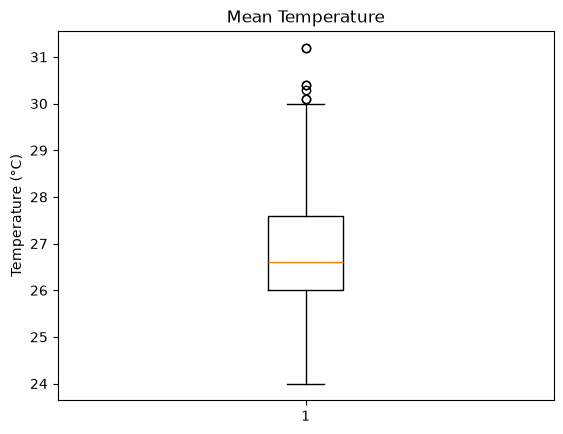

In [12]:
# mean temp

plt.boxplot(df["temp_mean"])

plt.title("Mean Temperature")
plt.ylabel("Temperature (°C)")

plt.show()

In [13]:
# orange line - median temp
### box - most of temp r b/w 26 to 28
# lines - temps are normally o from 24 to 30
# circle - some days are unusually hot,above 30


## most days had mean temp around 26 to 28, with unusually hot days above 30

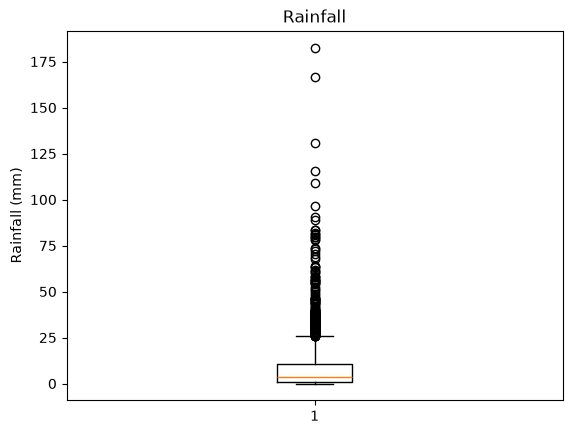

In [14]:
# rainfall  boxplot

plt.boxplot(df["rain"])

plt.title("Rainfall")
plt.ylabel("Rainfall (mm)")
plt.show()

In [15]:
## most days had low rainfall. Some days received much more rain, and these are shown as circles above the main box.

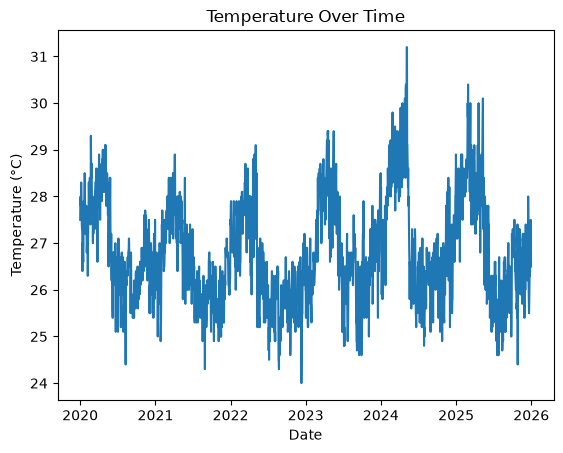

In [16]:

###- how daily mean temp changed from 2020 to 2025

plt.plot(df["date"], df["temp_mean"])

plt.title("Temperature Over Time")
plt.xlabel("Date")
plt.ylabel("Temperature (°C)")

plt.show()

In [17]:
## find which months get the most rainfall

monthly_rain = df.groupby("month")["rain"].mean()

print(monthly_rain)

month
1      2.354839
2      0.828824
3      2.241398
4      5.732778
5     19.801075
6     15.380000
7     15.070430
8     11.640323
9     10.998889
10    10.182258
11     6.558889
12     2.302151
Name: rain, dtype: float64


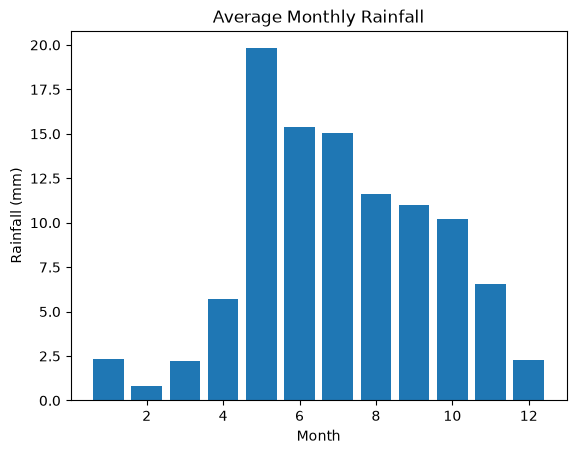

In [18]:
## monthly rainfall graph


plt.bar(monthly_rain.index, monthly_rain.values)

plt.title("Average Monthly Rainfall")
plt.xlabel("Month")
plt.ylabel("Rainfall (mm)")

plt.show()

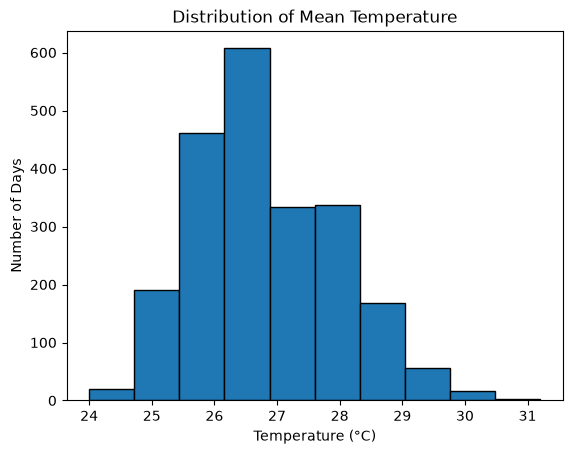

In [19]:
## check the distribution of each weather variable

plt.hist(df["temp_mean"],edgecolor='black')

plt.title("Distribution of Mean Temperature")
plt.xlabel("Temperature (°C)")
plt.ylabel("Number of Days")

plt.show()

In [20]:
##  Most days had temperatures between 26°C and 28°C. Very few days had temperatures below 25°C or above 30°C.

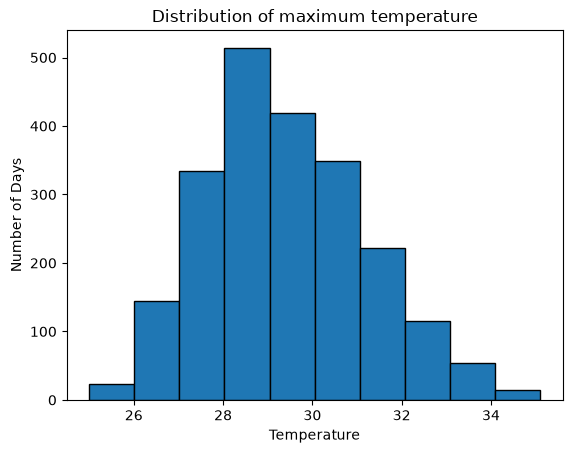

In [21]:
plt.hist(df["temp_max"],edgecolor="black")

plt.title("Distribution of maximum temperature")
plt.xlabel("Temperature")
plt.ylabel("Number of Days")
plt.show()

In [22]:
## Most days had a maximum temperature around 28 to 31°C, while only a few days were above 34°C.

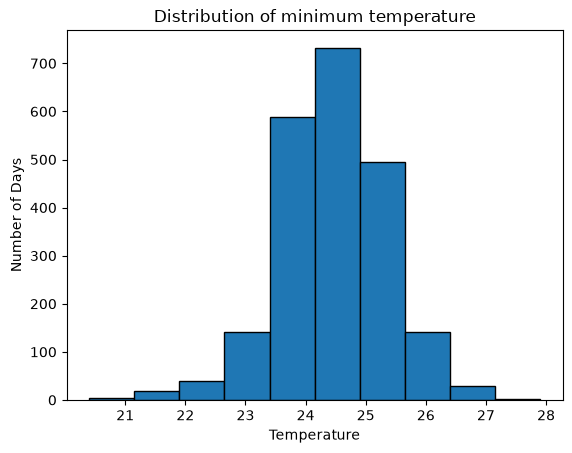

In [23]:
plt.hist(df["temp_min"],edgecolor="black")

plt.title("Distribution of minimum temperature")
plt.xlabel("Temperature")
plt.ylabel("Number of Days")
plt.show()

In [24]:
## Most days had a minimum temperature around 24 to 25°C, while very few days were below 22°C or above 27°C.

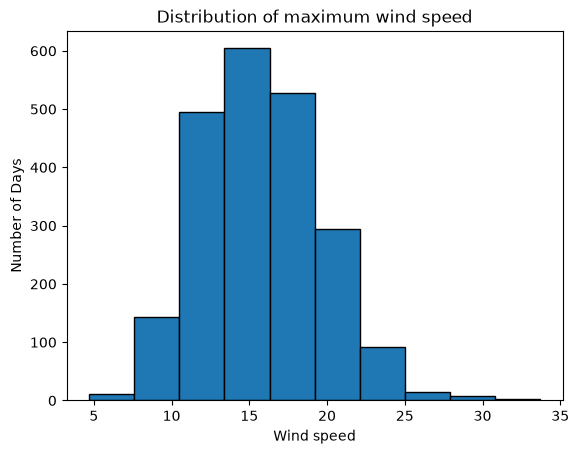

In [25]:
plt.hist(df["wind_max"],edgecolor="black")

plt.title("Distribution of maximum wind speed")
plt.xlabel("Wind speed")
plt.ylabel("Number of Days")
plt.show()

In [26]:
## Most days had wind speeds between 10 and 20 km/h. Wind speeds above 25 km/h were rare

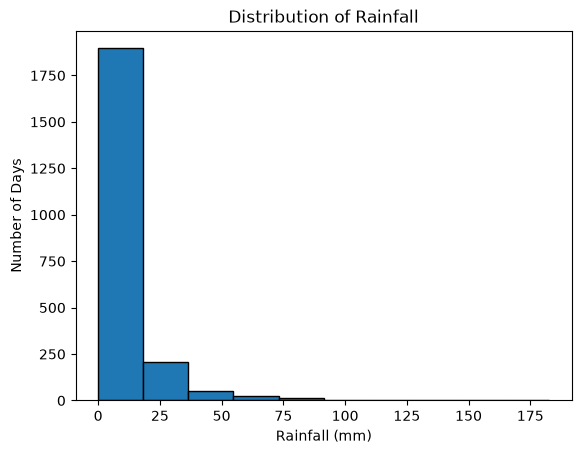

In [27]:
plt.hist(df["rain"], edgecolor="black")

plt.title("Distribution of Rainfall")
plt.xlabel("Rainfall (mm)")
plt.ylabel("Number of Days")

plt.show()

In [28]:
## tall bar near 0–25 mm means most days had low rainfall.
## Only a few days had heavy rainfall, such as 50 mm, 100 mm, or more

In [29]:
## Yearly rainfall


yearly_rain = df.groupby("year")["rain"].sum()
print(yearly_rain)

year
2020    2790.1
2021    3479.3
2022    2831.0
2023    2760.8
2024    4115.5
2025    2953.1
Name: rain, dtype: float64


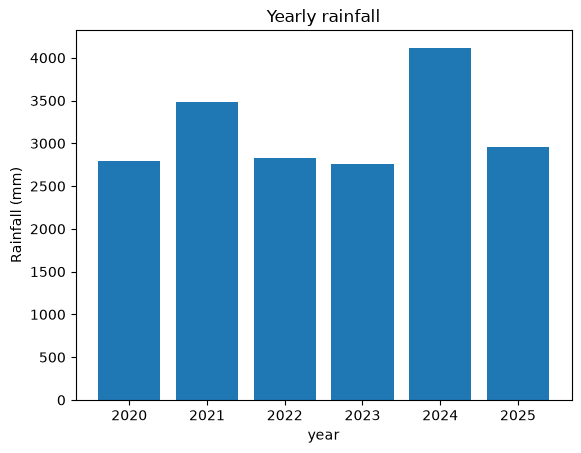

In [30]:
plt.bar(yearly_rain.index,yearly_rain.values)

plt.title("Yearly rainfall")
plt.xlabel("year")
plt.ylabel("Rainfall (mm)")

plt.show()

## find extreme weather days

In [31]:
# hottest_days

hottest_days= df.loc[df["temp_max"].idxmax()]   
print(hottest_days)

date           2024-02-27 00:00:00
temp_mean                     29.8
temp_max                      35.1
temp_min                      25.4
wind_max                      22.4
rain                           0.0
year                          2024
month                            2
total_range                    9.7
Name: 1518, dtype: object


In [32]:
# windiest_day

windiest_day = df.loc[df["wind_max"].idxmax()]
print(windiest_day)

date           2022-08-01 00:00:00
temp_mean                     25.1
temp_max                      26.1
temp_min                      24.3
wind_max                      33.7
rain                          90.8
year                          2022
month                            8
total_range                    1.8
Name: 943, dtype: object


In [33]:
# heaviest_rain


heaviest_rain = df.loc[df["rain"].idxmax()]
print(heaviest_rain)

date           2024-05-22 00:00:00
temp_mean                     26.5
temp_max                      27.3
temp_min                      25.3
wind_max                      21.2
rain                         182.6
year                          2024
month                            5
total_range                    2.0
Name: 1603, dtype: object


In [34]:
# coolest yr
year_avg = df.groupby("year")["temp_mean"].mean()
print(year_avg.min())
print(year_avg.idxmin())

26.408767123287667
2022


In [35]:
# wettest month

print(monthly_rain.max())
print(monthly_rain.idxmax())

19.801075268817204
5


In [36]:
# wettest yr
print(yearly_rain.idxmax())

2024


In [37]:

##   avg temp on rainy days and non rainy days

rainy = df[df["rain"]>0]["temp_mean"].mean()
non_rainy = df[df["rain"]== 0]["temp_mean"].mean()
print("Rainy days :",rainy)
print("Non-rainy days :", non_rainy)


Rainy days : 26.735045970795028
Non-rainy days : 27.25830903790087


In [38]:
## Check wind speed and rainfall

wind_rain = df[["wind_max","rain"]].corr()
print(wind_rain)

          wind_max      rain
wind_max  1.000000  0.162131
rain      0.162131  1.000000


In [39]:
## Wind speed and rainfall have a positive relationship,  when wind speed increases, rainfall increase. But the correlation is only 0.16, which is close to zero, so the relationship is very weak

In [40]:
year_avg = df.groupby("year")["temp_mean"].mean()

print(year_avg.max())
print(year_avg.idxmax())

27.149180327868848
2024


In [41]:
## Overall avg temperature

print(df["temp_mean"].mean())

26.81692518248175


In [42]:
X = df[["temp_max", "temp_min", "wind_max", "rain"]]
y = df["temp_mean"]

print(X.head())
print(y.head())

   temp_max  temp_min  wind_max  rain
0      29.8      25.1      14.4   0.7
1      30.4      25.4      16.4   0.0
2      31.0      25.2      13.7   0.6
3      30.5      25.1      15.5   1.4
4      30.2      25.3      13.0   0.4
0    27.5
1    27.9
2    28.0
3    27.8
4    27.8
Name: temp_mean, dtype: float64


In [43]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(    
    X, y, test_size=0.2, random_state=42            # test_size=0.2--> 80% of training and 20% of testing
)

In [44]:
print(X_train.shape)
print(X_test.shape)
print(y_train.shape)
print(y_test.shape)

(1753, 4)
(439, 4)
(1753,)
(439,)


In [45]:
from sklearn.linear_model import LinearRegression

model = LinearRegression()

model.fit(X_train, y_train)

,"fit_intercept fit_intercept: bool, default=TrueWhether to calculate the intercept for this model. If setto False, no intercept will be used in calculations(i.e. data is expected to be centered).",True
,"copy_X copy_X: bool, default=TrueIf True, X will be copied; else, it may be overwritten.",True
,"tol tol: float, default=1e-6The precision of the solution (`coef_`) is determined by `tol` whichspecifies the convergence criterion of the underlying solver. `tol` isset as `atol` and `btol` of :func:`scipy.sparse.linalg.lsqr` whenfitting on sparse training data. `tol` is set as `cond` of:func:`scipy.linalg.lstsq` when fitting on dense training data... versionadded:: 1.7.. versionchanged:: 1.9 Now supported on dense data, interpreted as the `cond` parameter.",1e-06
,"n_jobs n_jobs: int, default=NoneThe number of jobs to use for the computation. This will only providespeedup in case of sufficiently large problems, that is if firstly`n_targets > 1` and secondly `X` is sparse or if `positive` is setto `True`. ``None`` means 1 unless in a:obj:`joblib.parallel_backend` context. ``-1`` means using allprocessors. See :term:`Glossary <n_jobs>` for more details.",None
,"positive positive: bool, default=FalseWhen set to ``True``, forces the coefficients to be positive. Thisoption is only supported for dense arrays.For a comparison between a linear regression model with positive constraintson the regression coefficients and a linear regression without such constraints,see :ref:`sphx_glr_auto_examples_linear_model_plot_nnls.py`... versionadded:: 0.24",False
Name,Type,Value
"coef_ coef_: array of shape (n_features, ) or (n_targets, n_features)Estimated coefficients for the linear regression problem.If multiple targets are passed during the fit (y 2D), thisis a 2D array of shape (n_targets, n_features), while if onlyone target is passed, this is a 1D array of length n_features.","ndarray[float64](4,)","[ 0.49, 0.47, 0.01,-0. ]"
"feature_names_in_ feature_names_in_: ndarray of shape (`n_features_in_`,)Names of features seen during :term:`fit`. Defined only when `X`has feature names that are all strings... versionadded:: 1.0","ndarray[object](4,)","['temp_max','temp_min','wind_max','rain']"
"intercept_ intercept_: float or array of shape (n_targets,)Independent term in the linear model. Set to 0.0 if`fit_intercept = False`.",float64,0.7887
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,4
rank_ rank_: intRank of matrix `X`. Only available when `X` is dense.,int64,np.int64(4)


In [46]:
import joblib   # Loads a tool that can save our trained ML model

joblib.dump(model, "temp_model.pkl")

['temp_model.pkl']

In [47]:
y_pred = model.predict(X_test)

print(y_pred[:5])     # shows te 1st predictions by the model

[26.3689416  26.2142345  29.01545767 25.3497648  26.40408226]


In [48]:
# compare predicted temperature with the actual temperature

print("Actual:", y_test.iloc[:5].values)
print("Predicted:", y_pred[:5])

Actual: [26.7 26.  29.1 25.5 26.4]
Predicted: [26.3689416  26.2142345  29.01545767 25.3497648  26.40408226]


In [49]:
from sklearn.metrics import mean_absolute_error   # .metrics-- contain tools to check model performsnce
                                                  # mean_absolute_error--calculate avg difference b/w acyytal and predicted values

mae = mean_absolute_error(y_test, y_pred)    # y_test--actual temp 
                                             # y_pres-- temp predicted by model

print("MAE:", mae)           # avg prediction error is 0.21

MAE: 0.2097841825064293


In [50]:
from sklearn.metrics import r2_score #  s2_score-->how well our model predicts the target value(temp_mean)

r2 = r2_score(y_test, y_pred)

print("R² Score:", r2)

R² Score: 0.9379032575758193
